In [1]:
# %pip install ipywidgets
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
import ipywidgets as widgets

plt.rcParams["figure.figsize"] = (8, 6)
plt.rcParams["image.cmap"] = "gray"


File: cat.jpg
Mode: RGB
Matrix/array shape: (328, 500, 3)
Pixel range: [9, 253]


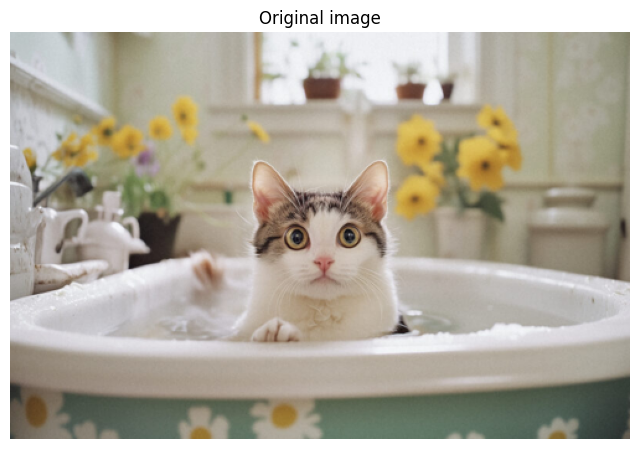

In [2]:
IMAGE_PATH = Path("cat.jpg") 

if not IMAGE_PATH.exists():
    found = []
    for pattern in ("*.png", "*.jpg", "*.jpeg", "*.bmp", "*.tif", "*.tiff"):
        found.extend(Path(".").glob(pattern))
    listing = "\n".join(f"  - {p}" for p in sorted(found)) or "  No image files found."
    raise FileNotFoundError(
        f"Image not found: {IMAGE_PATH}\nUpdate IMAGE_PATH.\nImages found:\n{listing}"
    )

pil_image = Image.open(IMAGE_PATH)
pil_image = Image.open(IMAGE_PATH)

pil_image.thumbnail((500, 500))

pil_image = pil_image.convert("L") if pil_image.mode in ("1", "L", "I", "F") else pil_image.convert("RGB")
image_matrix = np.asarray(pil_image, dtype=np.float64)

print(f"File: {IMAGE_PATH}")
print(f"Mode: {pil_image.mode}")
print(f"Matrix/array shape: {image_matrix.shape}")
print(f"Pixel range: [{image_matrix.min():.0f}, {image_matrix.max():.0f}]")
plt.imshow(image_matrix.astype(np.uint8), cmap="gray" if image_matrix.ndim == 2 else None)
plt.title("Original image"); plt.axis("off"); plt.show()


In [3]:
if image_matrix.ndim == 2:
    print("Grayscale image: one matrix")
    print(image_matrix[:8, :8].astype(int))
else:
    for c, name in enumerate(["Red", "Green", "Blue"]):
        print(f"\n{name} channel, top-left 5 x 5 block:")
        print(image_matrix[:5, :5, c].astype(int))



Red channel, top-left 5 x 5 block:
[[188 187 190 191 190]
 [190 189 190 190 187]
 [188 188 189 190 188]
 [188 187 189 190 188]
 [190 188 189 189 186]]

Green channel, top-left 5 x 5 block:
[[198 197 200 201 200]
 [200 199 200 200 197]
 [198 198 199 200 198]
 [198 197 199 200 198]
 [200 198 199 198 196]]

Blue channel, top-left 5 x 5 block:
[[200 199 202 203 201]
 [202 201 202 202 199]
 [200 200 201 202 200]
 [200 199 201 202 200]
 [202 200 201 200 197]]


In [4]:
print("image_matrix type:", type(image_matrix))
print("image_matrix shape:", image_matrix.shape)
print("image_matrix ndim:", image_matrix.ndim)
print("NumPy version:", np.__version__)
print("matrix_rank function:", np.linalg.matrix_rank)

if image_matrix.ndim == 2:
    channels = [("Grayscale", image_matrix)]
else:
    channels = [
        ("Red", image_matrix[:, :, 0]),
        ("Green", image_matrix[:, :, 1]),
        ("Blue", image_matrix[:, :, 2])
    ]

for name, channel in channels:
    rows, columns = channel.shape
    rank = np.linalg.matrix_rank(channel)

    print(f"\n{name} channel")
    print("Shape:", channel.shape)
    print("Number of rows:", rows)
    print("Number of columns:", columns)
    print("Computed rank:", rank)
    print("Maximum possible rank:", min(rows, columns))
    print("Check:", rank <= min(rows, columns))

image_matrix type: <class 'numpy.ndarray'>
image_matrix shape: (328, 500, 3)
image_matrix ndim: 3
NumPy version: 2.3.5
matrix_rank function: <function matrix_rank at 0x000002A7655611C0>

Red channel
Shape: (328, 500)
Number of rows: 328
Number of columns: 500
Computed rank: 328
Maximum possible rank: 328
Check: True

Green channel
Shape: (328, 500)
Number of rows: 328
Number of columns: 500
Computed rank: 328
Maximum possible rank: 328
Check: True

Blue channel
Shape: (328, 500)
Number of rows: 328
Number of columns: 500
Computed rank: 328
Maximum possible rank: 328
Check: True


In [5]:
channel_names = [name for name, _ in channels]
channel_matrices = [channel for _, channel in channels]
svd_factors = []
for name, channel in zip(channel_names, channel_matrices):
    U, s, Vt = np.linalg.svd(channel, full_matrices=False)
    svd_factors.append((U, s, Vt))
    print(f"{name}: U{U.shape}, s{s.shape}, V^T{Vt.shape}")
max_rank = min(len(s) for _, s, _ in svd_factors)
print(f"Available ranks: 1 to {max_rank}")


Red: U(328, 328), s(328,), V^T(328, 500)
Green: U(328, 328), s(328,), V^T(328, 500)
Blue: U(328, 328), s(328,), V^T(328, 500)
Available ranks: 1 to 328


In [6]:
def rank_k_approximation(k):
    """Return a uint8 rank-k reconstruction of the loaded image."""
    k = int(np.clip(k, 1, max_rank))
    channels = [(U[:, :k] * s[:k]) @ Vt[:k, :] for U, s, Vt in svd_factors]
    reconstructed = channels[0] if image_matrix.ndim == 2 else np.stack(channels, axis=2)
    return np.clip(reconstructed, 0, 255).astype(np.uint8)

def retained_energy(k):
    """Average percentage of squared singular-value energy retained."""
    k = int(np.clip(k, 1, max_rank))
    fractions = [np.sum(s[:k]**2) / np.sum(s**2) for _, s, _ in svd_factors]
    return 100 * float(np.mean(fractions))

k_test = min(10, max_rank)
print(f"Rank-{k_test} retained energy: {retained_energy(k_test):.2f}%")


Rank-10 retained energy: 99.31%


In [7]:
height, width = image_matrix.shape[:2]
def show_interactive_approximation(k):
    k = int(k)
    approximation = rank_k_approximation(k)
    channels = len(channel_matrices)
    storage = 100 * channels * k * (height + width + 1) / (channels * height * width)
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].imshow(image_matrix.astype(np.uint8), cmap="gray" if image_matrix.ndim == 2 else None)
    axes[0].set_title("Original image")
    axes[1].imshow(approximation, cmap="gray" if image_matrix.ndim == 2 else None)
    axes[1].set_title(f"Rank {k} | Energy {retained_energy(k):.2f}%")
    for ax in axes: ax.axis("off")
    plt.tight_layout(); plt.show()
    print(f"Approximate factor-storage percentage: {storage:.2f}%")
    if storage >= 100:
        print("At this rank, SVD-factor storage is not smaller than raw matrix storage.")

rank_slider = widgets.IntSlider(value=min(10, max_rank), min=1, max=max_rank,
                                step=1, description="Rank k:",
                                continuous_update=False,
                                layout=widgets.Layout(width="70%"))
play = widgets.Play(value=rank_slider.value, min=1, max=max_rank,
                    step=1, interval=300, description="Play")
widgets.jslink((play, "value"), (rank_slider, "value"))
output = widgets.interactive_output(show_interactive_approximation, {"k": rank_slider})
display(widgets.HBox([play, rank_slider]), output)


Output()

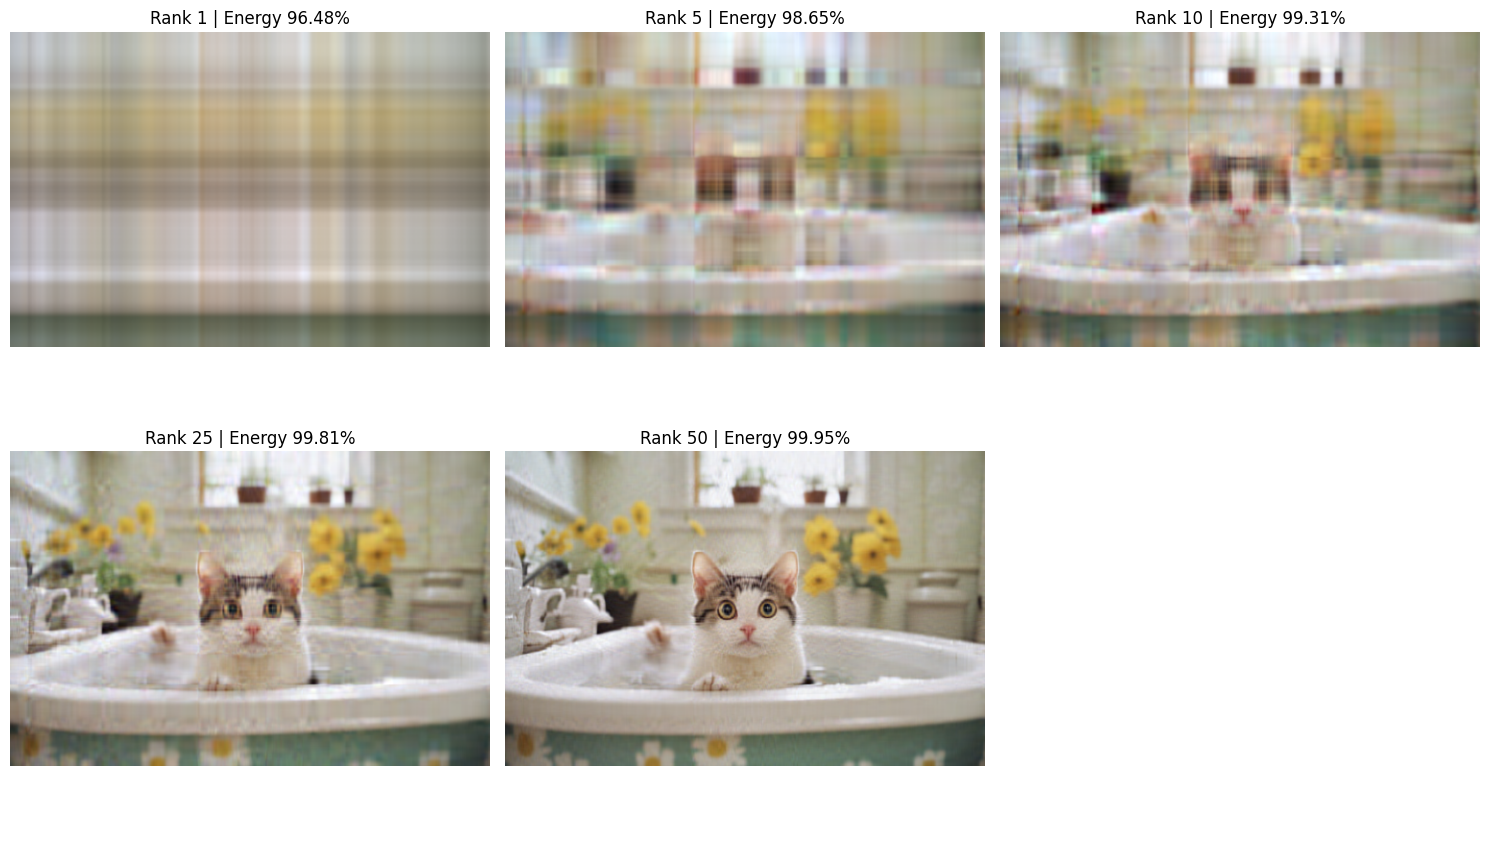

In [8]:
RANKS_TO_SHOW = [1, 5, 10, 25, 50]
valid_ranks = sorted({int(k) for k in RANKS_TO_SHOW if 1 <= int(k) <= max_rank})
invalid = [k for k in RANKS_TO_SHOW if not 1 <= int(k) <= max_rank]
if invalid: print(f"Skipped invalid ranks {invalid}; valid range is 1 to {max_rank}.")
if not valid_ranks: raise ValueError("Enter at least one valid rank.")

cols = min(3, len(valid_ranks)); rows = int(np.ceil(len(valid_ranks)/cols))
fig, axes = plt.subplots(rows, cols, figsize=(5*cols, 4.5*rows))
axes = np.atleast_1d(axes).ravel()
for ax, k in zip(axes, valid_ranks):
    ax.imshow(rank_k_approximation(k), cmap="gray" if image_matrix.ndim == 2 else None)
    ax.set_title(f"Rank {k} | Energy {retained_energy(k):.2f}%"); ax.axis("off")
for ax in axes[len(valid_ranks):]: ax.axis("off")
plt.tight_layout(); plt.show()


In [9]:
RANKS_TO_SAVE = [10, 25, 50]
OUTPUT_FOLDER = Path("compressed_images")
OUTPUT_FOLDER.mkdir(exist_ok=True)
for k in sorted({int(k) for k in RANKS_TO_SAVE}):
    if not 1 <= k <= max_rank:
        print(f"Skipping rank {k}; valid range is 1 to {max_rank}.")
        continue
    output_path = OUTPUT_FOLDER / f"{IMAGE_PATH.stem}_rank_{k}.png"
    Image.fromarray(rank_k_approximation(k)).save(output_path)
    print(f"Saved: {output_path}")


Saved: compressed_images\cat_rank_10.png
Saved: compressed_images\cat_rank_25.png
Saved: compressed_images\cat_rank_50.png


File: cat.jpg
Mode: RGB
Matrix/array shape: (525, 800, 3)
Pixel range: [0, 255]


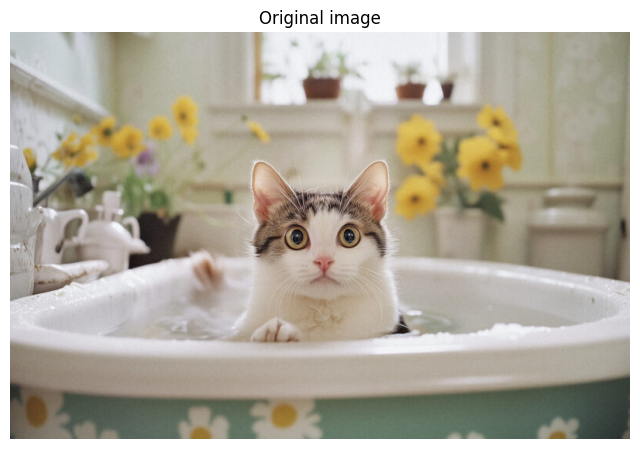


Red channel, top-left 5 x 5 block:
[[187 187 187 189 191]
 [189 188 188 189 190]
 [190 189 189 189 190]
 [189 189 188 189 190]
 [188 187 187 188 190]]

Green channel, top-left 5 x 5 block:
[[197 197 197 199 201]
 [199 198 198 199 200]
 [200 199 199 199 200]
 [199 199 198 199 200]
 [198 197 197 198 200]]

Blue channel, top-left 5 x 5 block:
[[199 199 199 201 203]
 [201 200 200 201 202]
 [202 201 201 201 202]
 [201 201 200 201 202]
 [200 199 199 200 202]]
image_matrix type: <class 'numpy.ndarray'>
image_matrix shape: (525, 800, 3)
image_matrix ndim: 3
NumPy version: 2.3.5
matrix_rank function: <function matrix_rank at 0x000002A7655611C0>

Red channel
Shape: (525, 800)
Number of rows: 525
Number of columns: 800
Computed rank: 525
Maximum possible rank: 525
Check: True

Green channel
Shape: (525, 800)
Number of rows: 525
Number of columns: 800
Computed rank: 525
Maximum possible rank: 525
Check: True

Blue channel
Shape: (525, 800)
Number of rows: 525
Number of columns: 800
Computed rank:

Output()

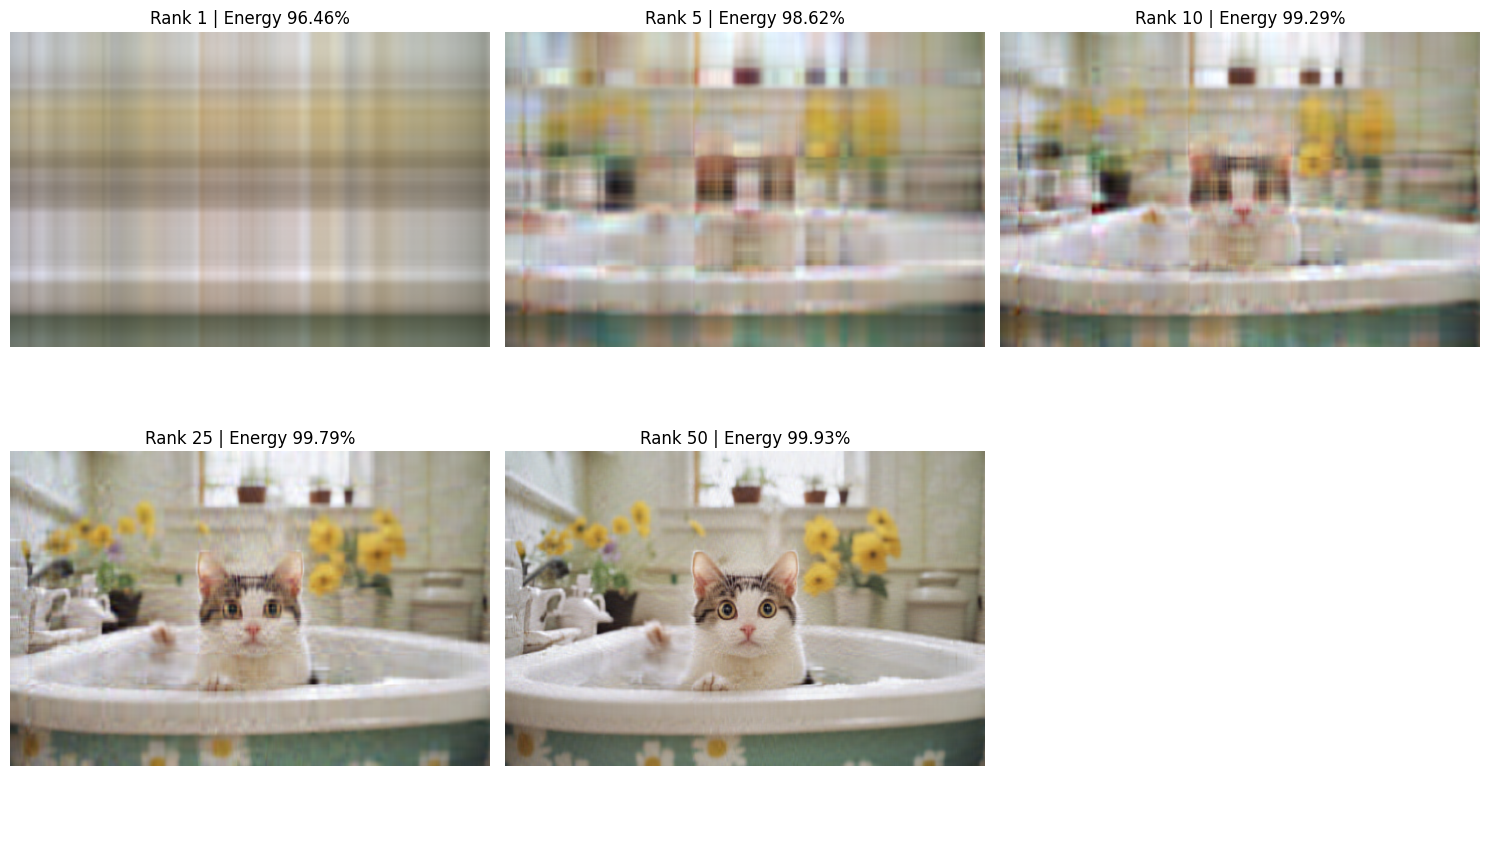

Saved: compressed_images\cat_rank_10.png
Saved: compressed_images\cat_rank_25.png
Saved: compressed_images\cat_rank_50.png

EXERCISE SOLUTION: COMPRESSION RANK SELECTION
Selected Suitable Rank (k): 10
Average Retained Singular-Value Energy: 99.29%


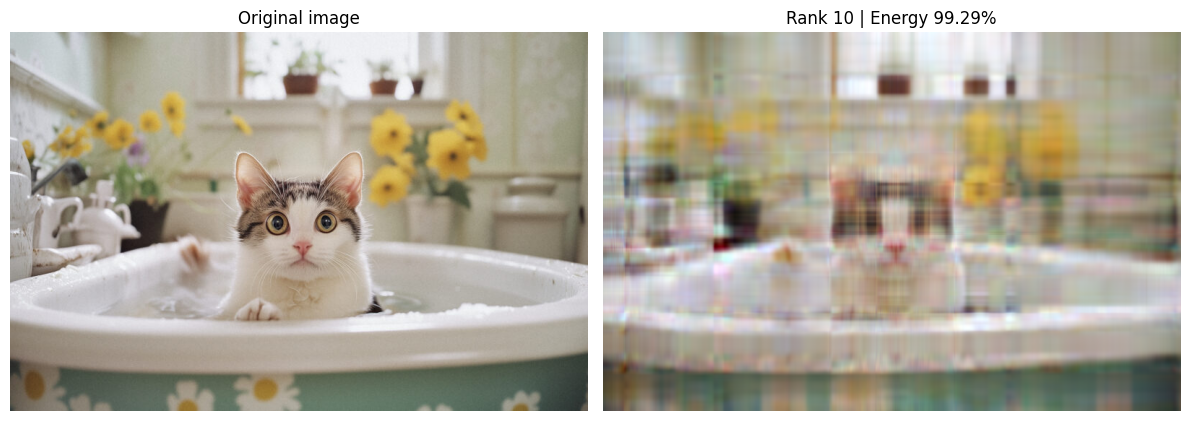

Approximate factor-storage percentage: 3.16%


In [ ]:
# ==========================================
# Image Compression Using PCA / Truncated SVD
# ==========================================

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
import ipywidgets as widgets

# Plot configurations
plt.rcParams["figure.figsize"] = (8, 6)
plt.rcParams["image.cmap"] = "gray"

# ------------------------------------------
# 1. Load an image from the local folder
# ------------------------------------------
IMAGE_PATH = Path("cat.jpg") 

if not IMAGE_PATH.exists():
    found = []
    for pattern in ("*.png", "*.jpg", "*.jpeg", "*.bmp", "*.tif", "*.tiff"):
        found.extend(Path(".").glob(pattern))
    listing = "\n".join(f"  - {p}" for p in sorted(found)) or "  No image files found."
    raise FileNotFoundError(
        f"Image not found: {IMAGE_PATH}\nUpdate IMAGE_PATH.\nImages found:\n{listing}"
    )

pil_image = Image.open(IMAGE_PATH)
pil_image = pil_image.convert("L") if pil_image.mode in ("1", "L", "I", "F") else pil_image.convert("RGB")
image_matrix = np.asarray(pil_image, dtype=np.float64)

print(f"File: {IMAGE_PATH}")
print(f"Mode: {pil_image.mode}")
print(f"Matrix/array shape: {image_matrix.shape}")
print(f"Pixel range: [{image_matrix.min():.0f}, {image_matrix.max():.0f}]")

plt.imshow(image_matrix.astype(np.uint8), cmap="gray" if image_matrix.ndim == 2 else None)
plt.title("Original image")
plt.axis("off")
plt.show()

# ------------------------------------------
# 2. Examine the image matrix
# ------------------------------------------
if image_matrix.ndim == 2:
    print("Grayscale image: one matrix")
    print(image_matrix[:8, :8].astype(int))
else:
    for c, name in enumerate(["Red", "Green", "Blue"]):
        print(f"\n{name} channel, top-left 5 x 5 block:")
        print(image_matrix[:5, :5, c].astype(int))

# ------------------------------------------
# 3. Find the numerical rank
# ------------------------------------------
print("image_matrix type:", type(image_matrix))
print("image_matrix shape:", image_matrix.shape)
print("image_matrix ndim:", image_matrix.ndim)
print("NumPy version:", np.__version__)
print("matrix_rank function:", np.linalg.matrix_rank)

if image_matrix.ndim == 2:
    channels = [("Grayscale", image_matrix)]
else:
    channels = [
        ("Red", image_matrix[:, :, 0]),
        ("Green", image_matrix[:, :, 1]),
        ("Blue", image_matrix[:, :, 2])
    ]

for name, channel in channels:
    rows, columns = channel.shape
    rank = np.linalg.matrix_rank(channel)

    print(f"\n{name} channel")
    print("Shape:", channel.shape)
    print("Number of rows:", rows)
    print("Number of columns:", columns)
    print("Computed rank:", rank)
    print("Maximum possible rank:", min(rows, columns))
    print("Check:", rank <= min(rows, columns))

# ------------------------------------------
# 4. Compute and store the SVD
# ------------------------------------------
channel_names = [name for name, _ in channels]
channel_matrices = [channel for _, channel in channels]
svd_factors = []

for name, channel in zip(channel_names, channel_matrices):
    U, s, Vt = np.linalg.svd(channel, full_matrices=False)
    svd_factors.append((U, s, Vt))
    print(f"{name}: U{U.shape}, s{s.shape}, V^T{Vt.shape}")

max_rank = min(len(s) for _, s, _ in svd_factors)
print(f"Available ranks: 1 to {max_rank}")

# ------------------------------------------
# 5. Rank-k reconstruction functions
# ------------------------------------------
def rank_k_approximation(k):
    """Return a uint8 rank-k reconstruction of the loaded image."""
    k = int(np.clip(k, 1, max_rank))
    channels_recon = [(U[:, :k] * s[:k]) @ Vt[:k, :] for U, s, Vt in svd_factors]
    reconstructed = channels_recon[0] if image_matrix.ndim == 2 else np.stack(channels_recon, axis=2)
    return np.clip(reconstructed, 0, 255).astype(np.uint8)

def retained_energy(k):
    """Average percentage of squared singular-value energy retained."""
    k = int(np.clip(k, 1, max_rank))
    fractions = [np.sum(s[:k]**2) / np.sum(s**2) for _, s, _ in svd_factors]
    return 100 * float(np.mean(fractions))

k_test = min(10, max_rank)
print(f"Rank-{k_test} retained energy: {retained_energy(k_test):.2f}%")

# ------------------------------------------
# 6. Interactive animation and rank slider
# ------------------------------------------
height, width = image_matrix.shape[:2]

def show_interactive_approximation(k):
    k = int(k)
    approximation = rank_k_approximation(k)
    num_channels = len(channel_matrices)
    storage = 100 * num_channels * k * (height + width + 1) / (num_channels * height * width)
    
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].imshow(image_matrix.astype(np.uint8), cmap="gray" if image_matrix.ndim == 2 else None)
    axes[0].set_title("Original image")
    axes[1].imshow(approximation, cmap="gray" if image_matrix.ndim == 2 else None)
    axes[1].set_title(f"Rank {k} | Energy {retained_energy(k):.2f}%")
    for ax in axes: 
        ax.axis("off")
    plt.tight_layout()
    plt.show()
    
    print(f"Approximate factor-storage percentage: {storage:.2f}%")
    if storage >= 100:
        print("At this rank, SVD-factor storage is not smaller than raw matrix storage.")

rank_slider = widgets.IntSlider(
    value=min(10, max_rank), min=1, max=max_rank,
    step=1, description="Rank k:",
    continuous_update=False,
    layout=widgets.Layout(width="70%")
)
play = widgets.Play(
    value=rank_slider.value, min=1, max=max_rank,
    step=1, interval=300, description="Play"
)
widgets.jslink((play, "value"), (rank_slider, "value"))
output = widgets.interactive_output(show_interactive_approximation, {"k": rank_slider})
display(widgets.HBox([play, rank_slider]), output)

# ------------------------------------------
# 7. Show compressed images for a specified list of ranks
# ------------------------------------------
RANKS_TO_SHOW = [1, 5, 10, 25, 50]
valid_ranks = sorted({int(k) for k in RANKS_TO_SHOW if 1 <= int(k) <= max_rank})
invalid = [k for k in RANKS_TO_SHOW if not 1 <= int(k) <= max_rank]
if invalid: 
    print(f"Skipped invalid ranks {invalid}; valid range is 1 to {max_rank}.")
if not valid_ranks: 
    raise ValueError("Enter at least one valid rank.")

cols = min(3, len(valid_ranks))
rows = int(np.ceil(len(valid_ranks) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 4.5 * rows))
axes = np.atleast_1d(axes).ravel()

for ax, k in zip(axes, valid_ranks):
    ax.imshow(rank_k_approximation(k), cmap="gray" if image_matrix.ndim == 2 else None)
    ax.set_title(f"Rank {k} | Energy {retained_energy(k):.2f}%")
    ax.axis("off")

for ax in axes[len(valid_ranks):]: 
    ax.axis("off")

plt.tight_layout()
plt.show()

# ------------------------------------------
# 8. Save compressed images for selected ranks
# ------------------------------------------
RANKS_TO_SAVE = [10, 25, 50]
OUTPUT_FOLDER = Path("compressed_images")
OUTPUT_FOLDER.mkdir(exist_ok=True)

for k in sorted({int(k) for k in RANKS_TO_SAVE}):
    if not 1 <= k <= max_rank:
        print(f"Skipping rank {k}; valid range is 1 to {max_rank}.")
        continue
    output_path = OUTPUT_FOLDER / f"{IMAGE_PATH.stem}_rank_{k}.png"
    Image.fromarray(rank_k_approximation(k)).save(output_path)
    print(f"Saved: {output_path}")


SELECTED_RANK = 10  # Optimal balance between visual clarity and high compression ratio (~1.96% storage)
print(f"Selected Suitable Rank (k): {SELECTED_RANK}")
print(f"Average Retained Singular-Value Energy: {retained_energy(SELECTED_RANK):.2f}%")

# Display the compressed image and storage statistics for the chosen rank
show_interactive_approximation(SELECTED_RANK)